# 03 — Phân tích Level 6: Reinforcement Learning cho Cờ Tàn (`Level6ReinforcementAgent`)

Notebook này phân tích kết quả huấn luyện và đánh giá **Level 6** (`Level6ReinforcementAgent`) trên các thế cờ tàn cuộc:
- **Afterstate TD($\lambda$)** cho 3 loại tàn cuộc: `KQK` (Vua + Hậu vs Vua), `KRK` (Vua + Xe vs Vua), `KPK` (Vua + Tốt vs Vua).
- **Batch REINFORCE** (bản đối chứng policy-gradient) trên `KRK`.
- Trực quan hóa Learning Curves và demo nước đi thực tế từ checkpoint `checkpoints/l6_krk_qtable.pkl`.

In [1]:
import json
import sys
import random
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "chess_ai").exists() and (PROJECT_ROOT.parent / "chess_ai").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from chess_ai.core.chess_env import ChessEnv
from chess_ai.agents.level6_reinforcement import Level6ReinforcementAgent, get_endgame_info
from chess_ai.ui.board_renderer import render_board_image

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

CURVE_PATH = PROJECT_ROOT / "results" / "training" / "krk_learning_curve.json"
CKPT_PATH = PROJECT_ROOT / "checkpoints" / "l6_krk_qtable.pkl"
print("Project root:", PROJECT_ROOT)
print("Curve file exists:", CURVE_PATH.exists(), "| Checkpoint exists:", CKPT_PATH.exists())

Project root: d:\Projects\TTNTNC_local\101_chess_agent\101_TTNTNC
Curve file exists: True | Checkpoint exists: True


## 1. Môi trường phần cứng, Siêu tham số & Tổng kết đánh giá

Đọc metadata và `stage_summary` từ `results/training/krk_learning_curve.json`.

In [2]:
with open(CURVE_PATH, "r", encoding="utf-8") as f:
    l6_data = json.load(f)

print(f"Experiment: {l6_data.get('experiment')} | Algorithm: {l6_data.get('algorithm')}")
print(f"Elapsed: {l6_data.get('elapsed_sec')}s | Checkpoint: {l6_data.get('checkpoint_path')} ({l6_data.get('checkpoint_size_kb')} KB)")
print("Endgames:", l6_data.get("endgames"))

print("\n=== Hardware Environment ===")
display(pd.DataFrame([l6_data["hardware_environment"]]))

print("=== Hyperparameters ===")
hp_rows = [{"parameter": k, "value": str(v)} for k, v in l6_data["hyperparameters"].items()]
display(pd.DataFrame(hp_rows))

print("=== Stage Summary (Greedy Evaluation) ===")
summary_rows = []
for stage_name, metrics in l6_data["stage_summary"].items():
    row = {"stage": stage_name}
    row.update(metrics)
    summary_rows.append(row)
summary_df = pd.DataFrame(summary_rows)
display(summary_df)

Experiment: Level6_RL_Endgames | Algorithm: afterstate_td_lambda_and_batch_reinforce
Elapsed: 286.59s | Checkpoint: checkpoints\l6_krk_qtable.pkl (2246.65 KB)
Endgames: ['KQK', 'KRK', 'KPK']

=== Hardware Environment ===


,device,platform,python_version,processor,cpu_count,torch_version
0,cpu,Windows-10-10.0.26200-SP0,3.11.16,"Intel64 Family 6 Model 154 Stepping 3, Genuine...",20,2.6.0+cu124


=== Hyperparameters ===


,parameter,value
0,config_path,configs/search_params.yaml
1,tabular_q_episodes_per_endgame,20000
2,reinforce_krk_episodes,2000
3,gamma,0.99
4,learning_rate,0.3
5,learning_rate_end,0.08
6,td_lambda,0.7
7,reinforce_lr,0.002
8,reinforce_batch_size,16
9,step_penalty,-0.005


=== Stage Summary (Greedy Evaluation) ===


,stage,elapsed_sec,q_states,final_train_win_rate,final_train_avg_plies,eval_games,greedy_win_rate,greedy_avg_plies
0,tabular_q_KQK,62.93,29031.0,0.962,19.65,100,1.00,17.66
1,tabular_q_KRK,72.11,31834.0,0.944,33.93,100,0.98,28.70
2,tabular_q_KPK,78.13,41877.0,0.741,30.48,100,0.75,31.55
3,reinforce_KRK,72.00,NaN,0.060,93.84,100,0.01,25.93


## 2. Learning Curves: Afterstate TD($\lambda$) (`KQK`, `KRK`, `KPK`) vs REINFORCE (`KRK`)

So sánh:
1. **Win Rate** theo Episode.
2. **Average Plies** mỗi ván theo Episode.
3. **Số lượng trạng thái (`q_states`)** đã khám phá theo Episode của 3 bảng Afterstate.

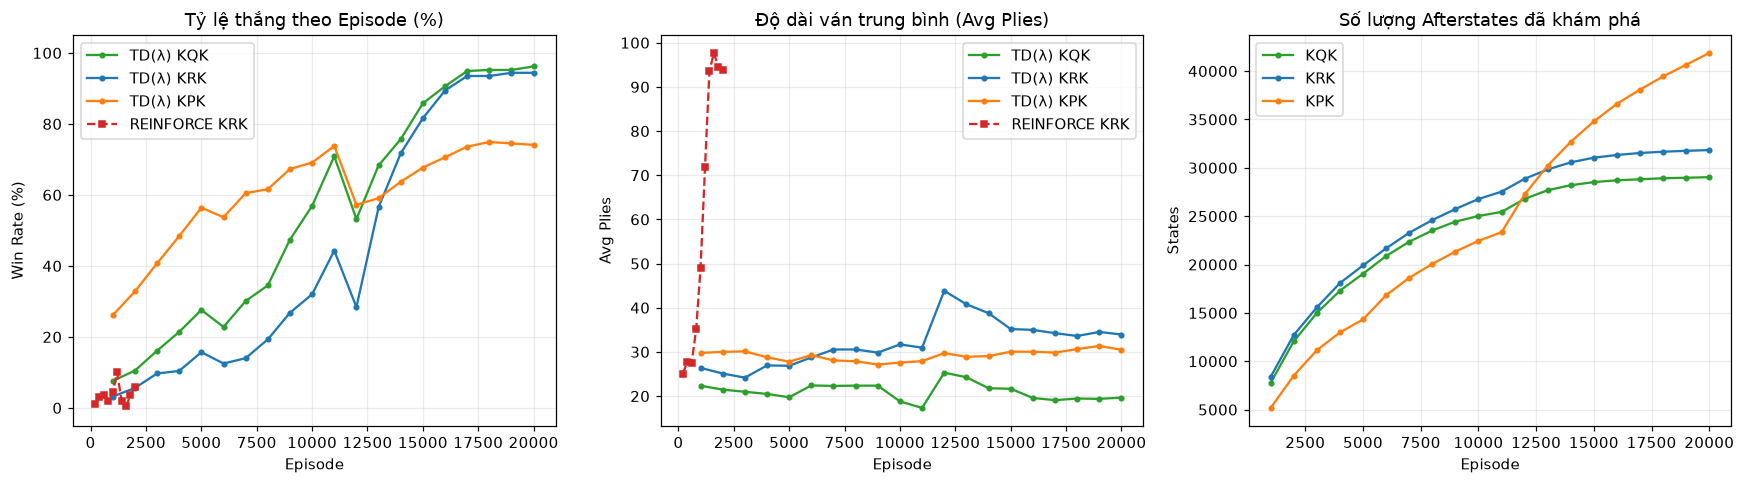

In [3]:
tab_curves = l6_data["tabular_q_curves"]
reinforce_df = pd.DataFrame(l6_data["reinforce_krk_curve"])

colors = {"KQK": "#2ca02c", "KRK": "#1f77b4", "KPK": "#ff7f0e", "REINFORCE_KRK": "#d62728"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Win Rate
ax = axes[0]
for eg, pts in tab_curves.items():
    df_eg = pd.DataFrame(pts)
    ax.plot(df_eg["episode"], df_eg["win_rate"] * 100, marker="o", markersize=3, label=f"TD(λ) {eg}", color=colors[eg])
ax.plot(reinforce_df["episode"], reinforce_df["win_rate"] * 100, marker="s", markersize=4, linestyle="--", label="REINFORCE KRK", color=colors["REINFORCE_KRK"])
ax.set_title("Tỷ lệ thắng theo Episode (%)")
ax.set_xlabel("Episode")
ax.set_ylabel("Win Rate (%)")
ax.set_ylim(-5, 105)
ax.legend()

# 2. Avg Plies
ax = axes[1]
for eg, pts in tab_curves.items():
    df_eg = pd.DataFrame(pts)
    ax.plot(df_eg["episode"], df_eg["avg_plies"], marker="o", markersize=3, label=f"TD(λ) {eg}", color=colors[eg])
ax.plot(reinforce_df["episode"], reinforce_df["avg_plies"], marker="s", markersize=4, linestyle="--", label="REINFORCE KRK", color=colors["REINFORCE_KRK"])
ax.set_title("Độ dài ván trung bình (Avg Plies)")
ax.set_xlabel("Episode")
ax.set_ylabel("Avg Plies")
ax.legend()

# 3. Q-States / Afterstates explored
ax = axes[2]
for eg, pts in tab_curves.items():
    df_eg = pd.DataFrame(pts)
    ax.plot(df_eg["episode"], df_eg["q_states"], marker="o", markersize=3, label=f"{eg}", color=colors[eg])
ax.set_title("Số lượng Afterstates đã khám phá")
ax.set_xlabel("Episode")
ax.set_ylabel("States")
ax.legend()

plt.tight_layout()
plt.show()

## 3. Demo & Trực quan hóa `Level6ReinforcementAgent`

Tải checkpoint `checkpoints/l6_krk_qtable.pkl` để:
1. Kiểm tra nước đi đề xuất trên 4 thế cờ tàn mẫu (`KQK`, `KRK` Trắng, `KPK`, `KRK` Đen) với `policy_mode="auto"`.
2. So sánh nước đi giữa `policy_mode="auto"` (Afterstate TD($\lambda$)) và `policy_mode="reinforce"` trên cùng một thế cờ `KRK`.
3. Mô phỏng nhanh 2 ván thực chiến (`KQK` và `KRK`) chống đối thủ ngẫu nhiên để quan sát khả năng dứt điểm chiếu hết.

pygame 2.6.1 (SDL 2.28.4, Python 3.11.16)
Hello from the pygame community. https://www.pygame.org/contribute.html


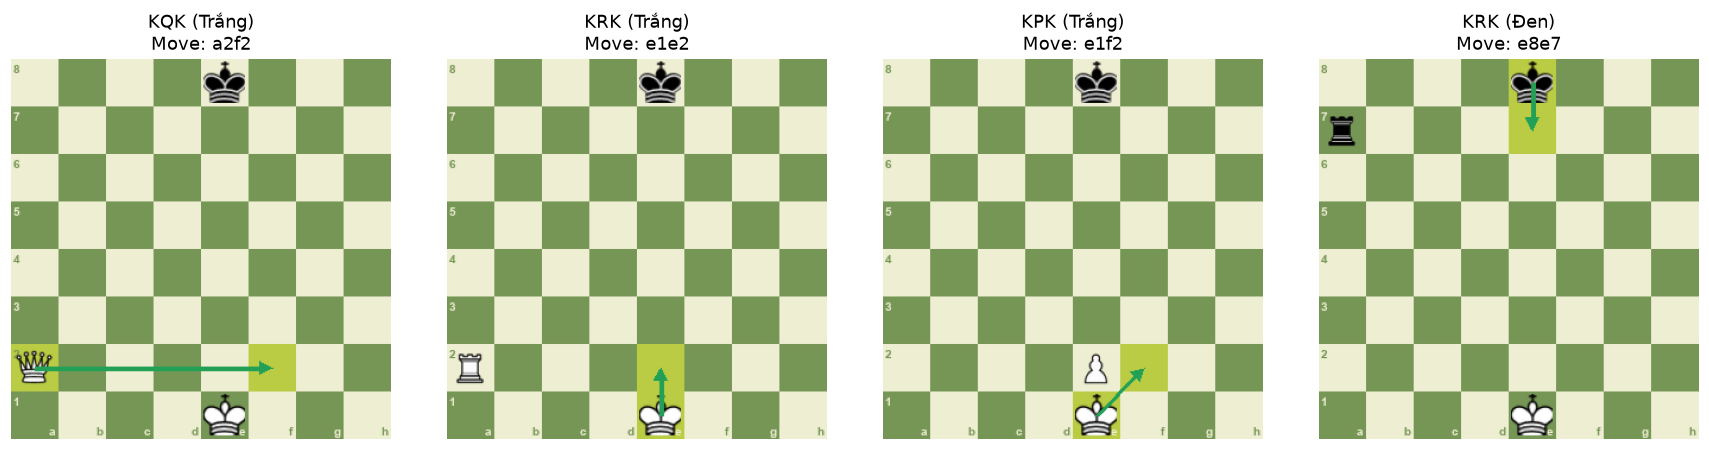

,position,endgame_type,attacker_is_white,move_uci
0,KQK (Trắng),KQK,True,a2f2
1,KRK (Trắng),KRK,True,e1e2
2,KPK (Trắng),KPK,True,e1f2
3,KRK (Đen),KRK,False,e8e7


In [4]:
agent_auto = Level6ReinforcementAgent(q_table_path=str(CKPT_PATH), policy_mode="auto")
agent_reinforce = Level6ReinforcementAgent(q_table_path=str(CKPT_PATH), policy_mode="reinforce")

sample_fens = {
    "KQK (Trắng)": "4k3/8/8/8/8/8/Q7/4K3 w - - 0 1",
    "KRK (Trắng)": "4k3/8/8/8/8/8/R7/4K3 w - - 0 1",
    "KPK (Trắng)": "4k3/8/8/8/8/8/4P3/4K3 w - - 0 1",
    "KRK (Đen)": "4k3/r7/8/8/8/8/8/4K3 b - - 0 1",
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
rows = []
for ax, (label, fen) in zip(axes, sample_fens.items()):
    env = ChessEnv(fen=fen)
    move = agent_auto.select_move(env)
    eg_info = get_endgame_info(env.board)
    eg_type, attacker_is_white = eg_info if eg_info else (None, None)
    rows.append({
        "position": label,
        "endgame_type": eg_type,
        "attacker_is_white": attacker_is_white,
        "move_uci": move.uci() if move else None,
    })
    img = render_board_image(env.board, move=move, board_size=320)
    ax.imshow(img)
    ax.set_title(f"{label}\nMove: {move.uci() if move else 'None'}")
    ax.axis("off")

plt.tight_layout()
plt.show()
display(pd.DataFrame(rows))

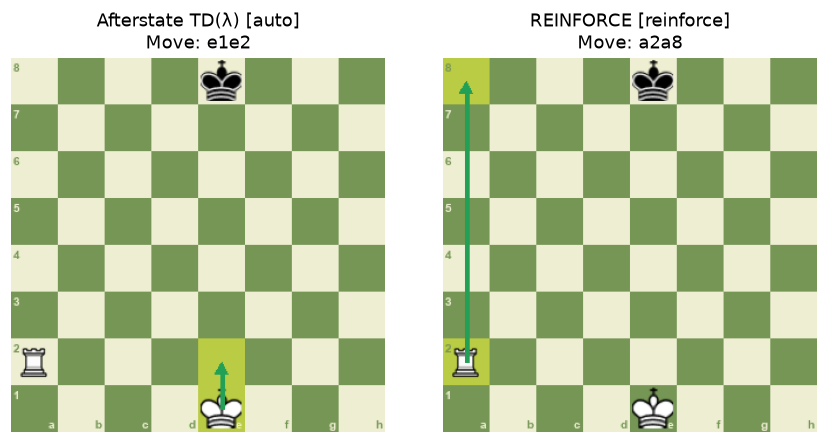

In [5]:
# So sánh policy_mode='auto' vs policy_mode='reinforce' trên KRK
krk_fen = "4k3/8/8/8/8/8/R7/4K3 w - - 0 1"
env_krk = ChessEnv(fen=krk_fen)
move_auto = agent_auto.select_move(env_krk)
move_reinf = agent_reinforce.select_move(env_krk)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, title, mv in [
    (axes[0], f"Afterstate TD(λ) [auto]\nMove: {move_auto.uci()}", move_auto),
    (axes[1], f"REINFORCE [reinforce]\nMove: {move_reinf.uci()}", move_reinf),
]:
    ax.imshow(render_board_image(env_krk.board, move=mv, board_size=320))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

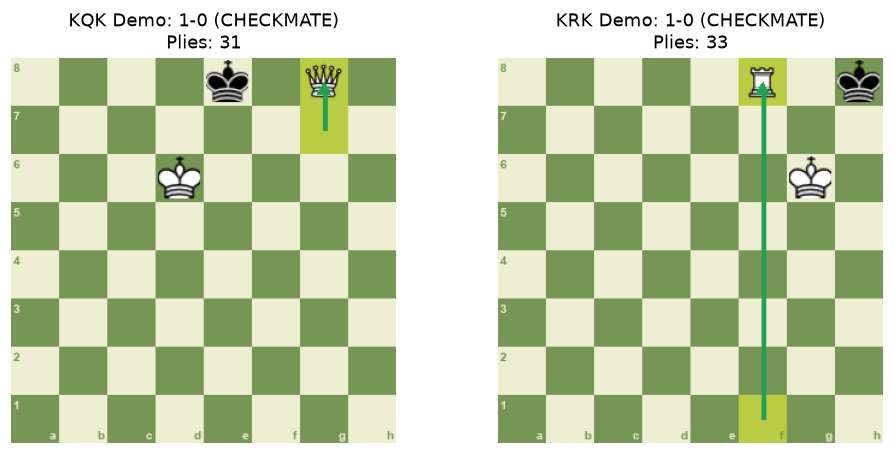

,endgame,plies,result,termination
0,KQK Demo,31,1-0,CHECKMATE
1,KRK Demo,33,1-0,CHECKMATE


In [6]:
# Mô phỏng nhanh 2 ván tàn cuộc (KQK và KRK) với đối thủ đi ngẫu nhiên
def play_endgame_demo(fen: str, agent: Level6ReinforcementAgent, max_plies: int = 80, seed: int = 42):
    rng = random.Random(seed)
    env = ChessEnv(fen=fen)
    attacker_color = env.board.turn
    plies = 0
    last_move = None
    while not env.is_terminal() and plies < max_plies:
        if env.board.turn == attacker_color:
            mv = agent.select_move(env)
        else:
            mv = rng.choice(list(env.board.legal_moves))
        env.step(mv)
        last_move = mv
        plies += 1
    outcome = env.board.outcome()
    result_str = outcome.result() if outcome else "Unfinished"
    term_str = outcome.termination.name if outcome else f"MaxPlies({max_plies})"
    return env, last_move, plies, result_str, term_str

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
sim_rows = []
for ax, (name, fen) in zip(axes, [
    ("KQK Demo", "4k3/8/8/8/8/8/Q7/4K3 w - - 0 1"),
    ("KRK Demo", "4k3/8/8/8/8/8/R7/4K3 w - - 0 1"),
]):
    env_end, last_mv, plies, res, term = play_endgame_demo(fen, agent_auto)
    sim_rows.append({"endgame": name, "plies": plies, "result": res, "termination": term})
    ax.imshow(render_board_image(env_end.board, move=last_mv, board_size=320))
    ax.set_title(f"{name}: {res} ({term})\nPlies: {plies}")
    ax.axis("off")

plt.tight_layout()
plt.show()
display(pd.DataFrame(sim_rows))